# Exercise 06 — Lasso Regression

**M.Sc. Data Science · I Semester · Machine Learning Lab**  
**Department Number:** 26-PDS-011 · **Student:** Thenmozhi K

## Aim
Implement Lasso Regression (L1 regularisation) on the housing dataset using fourth-degree polynomial features and compare it with ordinary linear regression.

## Dataset
Expected path: `Dataset/Housing.csv`. Obtain it from an authorised source and place it at the expected path. See the [dataset guide](../datasets/README.md).

## Algorithm / Workflow
1. Load Housing.csv and create dummy variables.
2. Split into train/test sets (80:20, random_state=42).
3. Standardise features.
4. Generate degree-4 polynomial features.
5. Fit ordinary LinearRegression and record train/test R².
6. Fit Lasso(alpha=0.1, max_iter=50000).
7. Compare model scores and train/test gaps in a table and bar chart.

## Implementation
The following code is copied from the existing `ex-06.py` program and split into notebook cells for interactive execution. The original Python program is unchanged.

Run cells from top to bottom. Outputs and charts are generated when executed with the dataset and required libraries available.

Original Features : 13
Polynomial Features : 2379
LINEAR REGRESSION
Training R2 : 0.994
Testing R2 : -2874.767


LASSO
Training R2 : 0.9922
Testing R2 : -13.4971
               Model  Train R2      Test R2
0  Linear Regression  0.994023 -2874.766987
1              Lasso  0.992212   -13.497146


/opt/hostedtoolcache/Python/3.12.15/x64/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 5.246819e+12, tolerance: 1.344e+11
  model = cd_fast.enet_coordinate_descent(


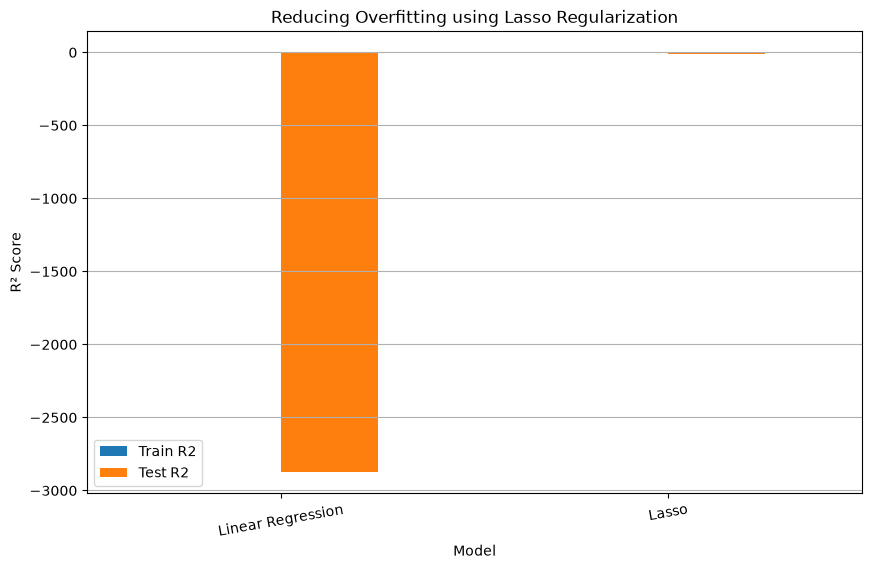

               Model  Train R2      Test R2   Difference
0  Linear Regression  0.994023 -2874.766987  2875.761010
1              Lasso  0.992212   -13.497146    14.489358


In [1]:
# EXERCISE – 06 (LASSO REGRESSION)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Lasso
from sklearn.metrics import r2_score

df = pd.read_csv("https://raw.githubusercontent.com/thenmozhi269/machine_learning_lab/refs/heads/main/datasets/Housing.csv")

df.head()

df = pd.get_dummies(df, drop_first=True)

df.head()

X = df.drop("price", axis=1)
y = df["price"]

X_train,X_test,y_train,y_test = train_test_split(
X,
y,
test_size=0.2,
random_state=42
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

poly = PolynomialFeatures(
    degree=4,
    include_bias=False
)

X_train_poly = poly.fit_transform(X_train_scaled)
X_test_poly = poly.transform(X_test_scaled)

print("Original Features :", X_train.shape[1])
print("Polynomial Features :", X_train_poly.shape[1])

linear = LinearRegression()

linear.fit(X_train_poly, y_train)

train_pred = linear.predict(X_train_poly)
test_pred = linear.predict(X_test_poly)

train_r2 = r2_score(y_train, train_pred)
test_r2 = r2_score(y_test, test_pred)

print("LINEAR REGRESSION")
print("Training R2 :", round(train_r2,4))
print("Testing R2 :", round(test_r2,4))

lasso = Lasso(
    alpha=0.1,
    max_iter=50000
)

lasso.fit(X_train_poly, y_train)

train_pred = lasso.predict(X_train_poly)
test_pred = lasso.predict(X_test_poly)

lasso_train = r2_score(y_train, train_pred)
lasso_test = r2_score(y_test, test_pred)

print("LASSO")
print("Training R2 :", round(lasso_train,4))
print("Testing R2 :", round(lasso_test,4))

comparison = pd.DataFrame({

    "Model":[
        "Linear Regression",
        "Lasso"
    ],

    "Train R2":[
        train_r2,
        lasso_train
    ],

    "Test R2":[
        test_r2,
        lasso_test
    ]
})

print(comparison)

comparison.plot(
    x="Model",
    y=["Train R2", "Test R2"],
    kind="bar",
    figsize=(10,6)
)

plt.title("Reducing Overfitting using Lasso Regularization")
plt.ylabel("R² Score")
plt.xticks(rotation=10)
plt.grid(axis="y")
plt.show()

comparison["Difference"] = comparison["Train R2"] - comparison["Test R2"]

print(comparison)


## Result summary from the practical record
The record reports ordinary linear regression train R² 0.9940 and test R² −2874.77. Lasso(alpha=0.1) had train R² 0.9922 and test R² −13.50. Overfitting was reduced, although test R² remained negative.

This summary is transcribed from the supplied Word record; it is not a fresh notebook execution. Run the cells to produce current outputs.

## Conclusion
Summarise findings from your execution and note limitations.

## Reproducibility
Record your Python version, dataset source/version and installed dependency versions.